# Beltrami Prior Tuning

`wCSET` can also be regularized with a purely geometric basis -- Laplace-Beltrami
eigenmodes of the cortical mesh (`mm.anatomy.source_space.compute_beltrami_harmonics`)
instead of the structural-connectome Laplacian (`compute_cst`) -- see
`../connectomic/beltrami_harmonics_notes.md` for the full design rationale (why this
basis needs its own orthonormalization, why hemispheres are independent, etc.).

This notebook tunes `compute_harmonic_prior(method="logpass")` -- the GBF paper's
(Wang et al. 2026, Nat Biomed Eng) logarithmic spectral prior,
`Sigma^-1 = diag(-beta/log(lambda))` -- against this mesh basis. Unlike the
`lowpass` sweeps (this notebook's own former content, and `harmonic-prior-tuning.ipynb`
on the connectome side), the swept parameter here is `cutoff`, not `beta`:
`beta` is mathematically inert for `logpass` in `wCSET`'s pipeline (it's a pure
uniform rescale, exactly cancelled by `prepare_kernel`'s trace-renormalization
before the ridge solve -- verified analytically and on real data, see
`compute_harmonic_prior`'s docstring in
`mindmap/analysis/functional/inverse/utils.py`), while `cutoff` (how many
leading modes are kept, and the normalization reference) is what actually
shapes the prior. `cutoff` has no default for `logpass` -- we've been using
the paper's own `S=300` without ever checking whether that's a good choice
for *this* mesh spectrum specifically, which has a very different shape from
the paper's own (spread out, long tail -- see `beltrami_harmonics_notes.md`).
This sweep checks that.

Uses the same simulated `simf10` dataset (known ground truth) and the same
evaluation methodology as `harmonic-prior-tuning.ipynb`, runs 1-10, for direct
comparability. `depth=0` throughout (not the sibling notebooks' `depth=0.5`):
the paper's method has no depth term at all, and mixing one in would be tuning
`cutoff` for a hybrid the paper doesn't describe.

## 🧪 - Experiment setup
- `fwd`: Forward solution
- `eigvec`/`eigval`: Mesh-Beltrami eigendecomposition of the source space's own
  cortex-only per-hemisphere mesh (`compute_beltrami_harmonics`) -- purely
  geometric, no connectome/connectivity input at all
- `runs`: simf10 runs to sweep over -- `ave`/`ncov`/`gold`/`source` are run-dependent
  and reloaded per run inside the main loop; everything else here is subject-level
  and loaded/computed once

In [1]:
# imports
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

import mindmap as mm
import mne

from mindmap.analysis.functional.inverse.utils import compute_harmonic_prior
from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
runs = [str(r) for r in range(1, 11)]

# subject-level data (run-independent)
fwd = dm.load(sub, "fwd", desc="inv")

# Mesh-Beltrami eigendecomposition -- purely geometric, no connectome input.
# Timing is load-dependent (seen 4s-110s across sessions, same variance the
# connectome's own eigh already shows -- see beltrami_harmonics_notes.md).
# No formal "eig"-style cache registered for this basis yet (only the
# connectome's `eig` datatype has one), so computed fresh here.
t0 = time.time()
eigvec, eigval = mm.anatomy.source_space.compute_beltrami_harmonics(fwd["src"])
print(f"mesh-Beltrami eigendecomposition: {time.time()-t0:.1f}s, shape={eigvec.shape}")

simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub}"/"simulator")
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

# crop
tmin, tmax = -0.05, 0.15

/home/nino/Code/mindmap/mindmap/anatomy/source_space/spectral.py:88: RuntimeWarning: _cortex_triangulation: 1 of 3748 dipoles have no incident all-cortex face and will get zero representation in the Beltrami harmonic basis (vertno indices: [61429])
  warnings.warn(


mesh-Beltrami eigendecomposition: 4.2s, shape=(7465, 7464)


## 🎚️ - Cutoff sweep

`cutoff` sets both how many leading (lowest-eigenvalue) modes are kept and
the normalization reference (`eigval[cutoff-1]`) that the retained
eigenvalues are divided by before `-log(...)` is applied -- together this
fixes where the prior's flat-plateau-then-wall shape actually puts its wall.
The grid below brackets the paper's own `S=300` on both sides (`200`/`300`/
`450`) while spanning nearly three orders of magnitude against this mesh's
~7,464-mode spectrum, so the sweep can tell us whether this basis's own
optimum lands near the paper's value or somewhere else -- unlike the old
`beta` sweep here, there's no participation-ratio translation needed:
`cutoff` is already directly a mode count, not a decay rate to convert.

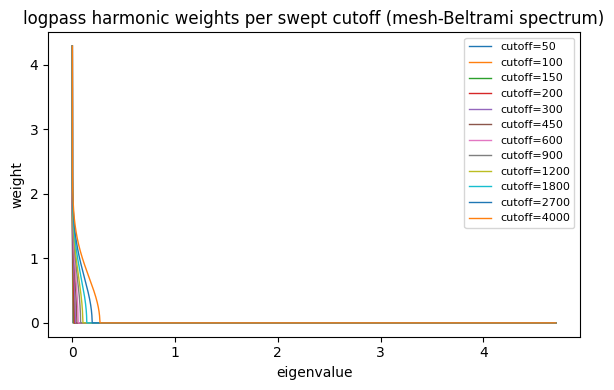

In [2]:
cutoffs = [50, 100, 150, 200, 300, 450, 600, 900, 1200, 1800, 2700, 4000]

fig, ax = plt.subplots(figsize=(6, 4))
for cutoff in cutoffs:
    w = compute_harmonic_prior(eigval, method="logpass", cutoff=cutoff)
    ax.plot(eigval, w, lw=1, label=f"cutoff={cutoff}")
ax.set_xlabel("eigenvalue")
ax.set_ylabel("weight")
ax.set_title("logpass harmonic weights per swept cutoff (mesh-Beltrami spectrum)")
ax.legend(fontsize=8)
fig.tight_layout()

## 🎯 - Solve and evaluate across runs x cutoffs

Same construction as `harmonic-prior-tuning.ipynb`: for each of `runs` x
`cutoffs`, solve with `wCSET` (`harmonic_method="logpass"`, `depth=0`,
`eigenvectors`/`eigenvalues` from the mesh-Beltrami basis), then score
against that run's own `gold`: spatial correlation over the whole cropped
window, average precision (AP) at half-rising-phase and peak-phase, and
peak-localization-error at half-rising-phase. Registered into `metrics`
under `label=f"cutoff={cutoff}"`. `harm` is left at its (inert) default --
see the intro above.

`sLORETA` solved once per run too (no `cutoff`, no basis at all) as an
external reference point, same as the connectome-side notebook.

In [3]:
metrics = mm.metric.MetricSuite(f"Beltrami Prior Tuning {sub} logpass sweep")
scalar_rows = []

for run in tqdm(runs, desc="runs"):
    ave = dm.load(sub, "ave", run=run)
    ncov = dm.load(sub, "cov", run=run)
    gold = dm.load(sub, "gold", run=run)

    data = ave.copy().crop(tmin=tmin, tmax=tmax)
    ground = gold.copy().crop(tmin=tmin, tmax=tmax)

    snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(-0.4, -0.2), noise_cov=ncov)
    lambda2 = max(0.01, 1.0 / (snr.max()**2))

    hrp = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)[0]
    pp = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]

    src_seed = dm.load(sub, "source", run=run)
    true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)

    def evaluate_and_register(label, sol):
        # spatial correlation over the whole cropped window
        corr = np.asarray(mm.analysis.inverse.compute_stc_correlation(ground, sol, mode="spatial", method="pearson"))
        metrics.register("correlation", corr, Label=label, times=ground.times)

        pr_hrp = mm.core.calc_pr_curve(ground.data[:, hrp] > 0, sol.data[:, hrp])
        precision_hrp_grid, recall_grid = mm.core.resample_pr_curve(pr_hrp["precision"], pr_hrp["recall"])
        metrics.register("precision_hrp", precision_hrp_grid, Label=label, recall=recall_grid)

        pr_pp = mm.core.calc_pr_curve(ground.data[:, pp] > 0, sol.data[:, pp])
        precision_pp_grid, recall_pp_grid = mm.core.resample_pr_curve(pr_pp["precision"], pr_pp["recall"])
        metrics.register("precision_pp", precision_pp_grid, Label=label, recall=recall_pp_grid)

        # peak localization error at half-rising-phase only
        hit_hrp = find_peak_localization_error(sol.data[:, hrp], true_source_mask, dipole_positions)
        metrics.register("localization_error_hrp", hit_hrp["distance_mm"], Label=label)

        return pr_hrp["ap"], pr_pp["ap"], hit_hrp["distance_mm"]

    for cutoff in cutoffs:
        inv = mm.analysis.inverse.wCSET(
            forward = fwd,
            noise_cov = ncov,
            depth = 0,
            eigenvectors = eigvec,
            eigenvalues = eigval,
            harmonic_method = "logpass",
            cutoff = cutoff,
        )
        sol = inv.solve(data, lambda2)
        ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register(f"cutoff={cutoff}", sol)
        scalar_rows.append(dict(run=run, method="logpass", cutoff=cutoff, ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp))

    # sLORETA reference: no cutoff, no basis at all -- external baseline.
    inv_sloreta = mne.minimum_norm.make_inverse_operator(
        info = data.info,
        forward = fwd,
        noise_cov = ncov,
        fixed = True,
        depth = None,
    )
    sol_sloreta = mne.minimum_norm.apply_inverse(data, inv_sloreta, lambda2, method="sLORETA")
    ap_hrp, ap_pp, loc_err_hrp = evaluate_and_register("sloreta", sol_sloreta)
    scalar_rows.append(dict(run=run, method="sloreta", cutoff=np.nan, ap_hrp=ap_hrp, ap_pp=ap_pp, loc_err_hrp=loc_err_hrp))

scalar_df = pd.DataFrame(scalar_rows)

runs:   0%|          | 0/10 [00:00<?, ?it/s]

    Created an SSP operator (subspace dimension = 1)


Computing rank from covariance with rank=None


    Using tolerance 4e-15 (2.2e-16 eps * 203 dim * 0.088  max singular value)


    Estimated rank (eeg): 202


    EEG: rank 202 computed from 203 data channels with 1 projector


... (402 outputs left out)

    sLORETA...


[done]


runs: 100%|██████████| 10/10 [02:58<00:00, 17.18s/it]

runs: 100%|██████████| 10/10 [02:58<00:00, 17.90s/it]

## 📊 - Visualization

Correlation vs. time, localization error at hrp, and precision-recall at hrp/pp --
one colored line/box per `cutoff`, mean +/- CI across the 10 runs.

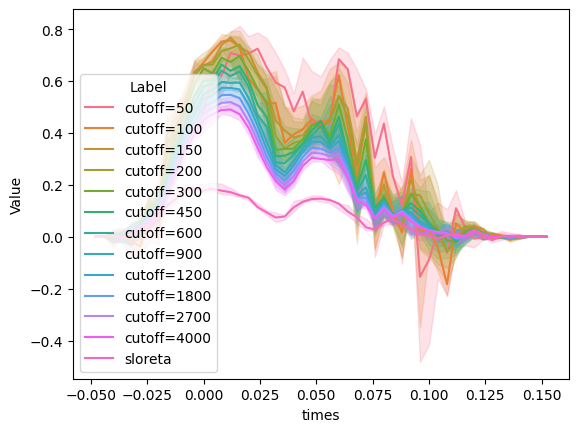

In [4]:
# median +/- IQR across the 10 runs, same convention as the connectome-side
# notebook -- more robust than mean+-SD since the 10 runs are different source
# locations (real heterogeneity), not noise repeats of one signal.
metrics.plot.line(
    group_by = "Label",
    metric = "correlation",
    x = "times",
    estimator = "median",
    errorbar = ("pi", 50),
);

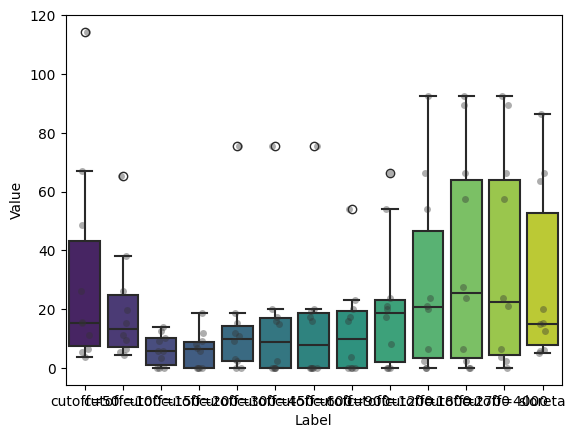

In [5]:
metrics.plot.box(
    group_by = "Label",
    metric = "localization_error_hrp",
);

AP by method/cutoff (mean +/- std across runs 1-10):


ap_hrp               ap_pp           loc_err_hrp           
                    mean       std      mean       std        mean        std
method  cutoff                                                               
logpass 50.0    0.420246  0.099968  0.828823  0.079815   31.420811  35.685300
        100.0   0.485137  0.143644  0.817031  0.086013   20.174367  19.094340
        150.0   0.486534  0.107702  0.813955  0.095381    6.086716   5.222169
        200.0   0.470313  0.102192  0.814721  0.084809    6.054525   6.262793
        300.0   0.444501  0.098928  0.800853  0.083778   14.663410  22.363515
        450.0   0.424851  0.093270  0.789981  0.086956   14.639446  23.020226
        600.0   0.412433  0.085483  0.787513  0.087870   14.838101  23.219345
        900.0   0.396646  0.075594  0.782641  0.089163   13.437096  17.103583
        1200.0  0.386751  0.070360  0.779990  0.091262   21.098177  22.740334
        1800.0  0.374507  0.065893  0.776147  0.094013   28.677450  31.851461
        2700.0  0.364134  0.063266  0.771943  0.096881   36.593257  36.901888
        4000.0  0.354789  0.062495  0.767725  0.099462   36.322887  36.745617
sloreta NaN     0.348898  0.065475  0.730147  0.100044   29.594661  30.243451

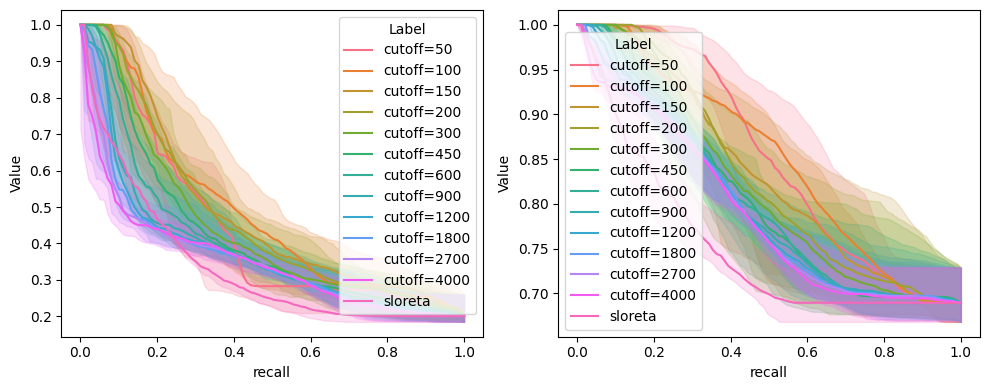

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
metrics.plot.line(group_by="Label", metric="precision_hrp", x="recall", estimator="median", errorbar=("pi", 50), ax=axes[0])
metrics.plot.line(group_by="Label", metric="precision_pp", x="recall", estimator="median", errorbar=("pi", 50), ax=axes[1])
fig.tight_layout()

print("AP by method/cutoff (mean +/- std across runs 1-10):")
scalar_df.groupby(["method", "cutoff"], dropna=False)[["ap_hrp", "ap_pp", "loc_err_hrp"]].agg(["mean", "std"])